<a href="https://colab.research.google.com/github/JuanitaRozo/Generaci-n/blob/main/DCGAN_FashionMNIST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os, random, csv, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid, save_image

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUT = Path('resultados_dcgan'); OUT.mkdir(exist_ok=True)
print('PyTorch:', torch.__version__, '| Dispositivo:', DEVICE)

PyTorch: 2.14.1+cu130 | Dispositivo: cuda


100%|██████████| 26.4M/26.4M [00:02<00:00, 10.9MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 164kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.08MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 24.2MB/s]


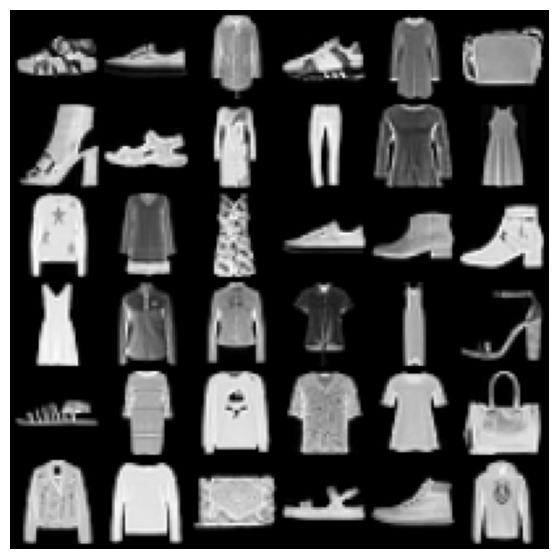

Imágenes: 60000 | Tensor: (128, 1, 32, 32)


In [ ]:
BATCH_SIZE = 128 if DEVICE.type == 'cuda' else 64
EPOCHS = 5  # aumentar a 10-20 para experimentar
LATENT_DIM = 100
transform = transforms.Compose([
    transforms.Resize(32), transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])
dataset = datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True,
                    num_workers=2 if DEVICE.type == 'cuda' else 0, drop_last=True)
real, labels = next(iter(loader))
plt.figure(figsize=(7,7)); plt.axis('off')
plt.imshow(make_grid((real[:36]+1)/2, nrow=6).permute(1,2,0).numpy()); plt.show()
print('Imágenes:',len(dataset),'| Tensor:', tuple(real.shape))

In [ ]:
class Generator(nn.Module):
    def __init__(self, zdim=100):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(zdim, 256, 4, 1, 0, bias=False), nn.BatchNorm2d(256), nn.ReLU(True),
            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False), nn.BatchNorm2d(128), nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False), nn.BatchNorm2d(64), nn.ReLU(True),
            nn.ConvTranspose2d(64, 1, 4, 2, 1, bias=False), nn.Tanh()
        )
    def forward(self,z): return self.net(z)

class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1,64,4,2,1), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64,128,4,2,1,bias=False), nn.BatchNorm2d(128), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(128,256,4,2,1,bias=False), nn.BatchNorm2d(256), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(256,1,4,1,0)
        )
    def forward(self,x): return self.net(x).flatten()

def init_weights(m):
    if isinstance(m,(nn.Conv2d,nn.ConvTranspose2d)):
        nn.init.normal_(m.weight.data,0.0,0.02)
    elif isinstance(m,nn.BatchNorm2d):
        nn.init.normal_(m.weight.data,1.0,0.02)
        nn.init.constant_(m.bias.data,0)
G=Generator(LATENT_DIM).to(DEVICE); D=Discriminator().to(DEVICE)
G.apply(init_weights); D.apply(init_weights)
with torch.no_grad():
    fake=G(torch.randn(4,LATENT_DIM,1,1,device=DEVICE))
    assert fake.shape==(4,1,32,32)
    assert D(fake).shape==(4,)
print('Verificación de dimensiones correcta')

Verificación de dimensiones correcta


In [ ]:
criterion=nn.BCEWithLogitsLoss()
opt_g=torch.optim.Adam(G.parameters(),lr=0.0002,betas=(0.5,0.999))
opt_d=torch.optim.Adam(D.parameters(),lr=0.0002,betas=(0.5,0.999))
fixed_noise=torch.randn(36,LATENT_DIM,1,1,device=DEVICE)
history=[]
start=time.time()
for epoch in range(1,EPOCHS+1):
    G.train(); D.train(); d_total=g_total=0.0
    for real,_ in loader:
        real=real.to(DEVICE); bs=real.size(0)
        z=torch.randn(bs,LATENT_DIM,1,1,device=DEVICE)
        fake=G(z)
        opt_d.zero_grad(set_to_none=True)
        d_loss=(criterion(D(real),torch.ones(bs,device=DEVICE))+
                criterion(D(fake.detach()),torch.zeros(bs,device=DEVICE)))
        d_loss.backward(); opt_d.step()
        opt_g.zero_grad(set_to_none=True)
        g_loss=criterion(D(fake),torch.ones(bs,device=DEVICE))
        g_loss.backward(); opt_g.step()
        d_total+=d_loss.item(); g_total+=g_loss.item()
    avg_d=d_total/len(loader); avg_g=g_total/len(loader)
    history.append({'epoch':epoch,'loss_d':avg_d,'loss_g':avg_g})
    G.eval()
    with torch.no_grad():
        samples=(G(fixed_noise).cpu()+1)/2
    save_image(samples,OUT/f'epoch_{epoch:02d}.png',nrow=6)
    print(f'Época {epoch}/{EPOCHS} | D={avg_d:.4f} | G={avg_g:.4f}')
print('Minutos:',round((time.time()-start)/60,2))
with open(OUT/'perdidas.csv','w',newline='',encoding='utf-8') as f:
    writer=csv.DictWriter(f,fieldnames=['epoch','loss_d','loss_g']);writer.writeheader();writer.writerows(history)
torch.save({'generator':G.state_dict(),'discriminator':D.state_dict(),
            'latent_dim':LATENT_DIM,'epochs':EPOCHS},OUT/'modelo_dcgan.pt')

Época 1/5 | D=0.5788 | G=2.7366
Época 2/5 | D=0.8253 | G=1.7051
Época 3/5 | D=0.8438 | G=1.7006
Época 4/5 | D=0.6643 | G=2.0539
Época 5/5 | D=0.5231 | G=2.4347
Minutos: 1.84


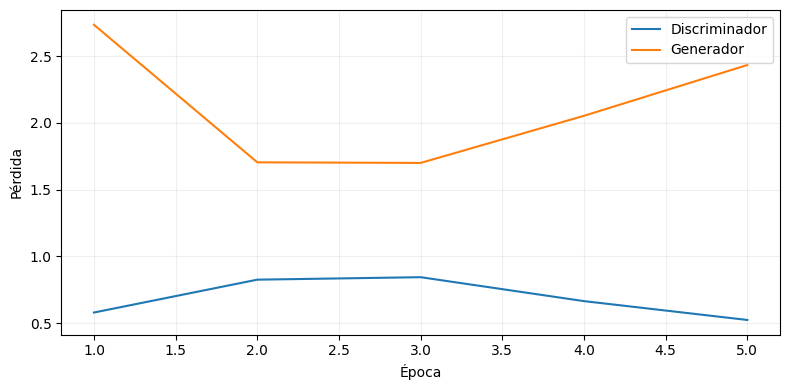

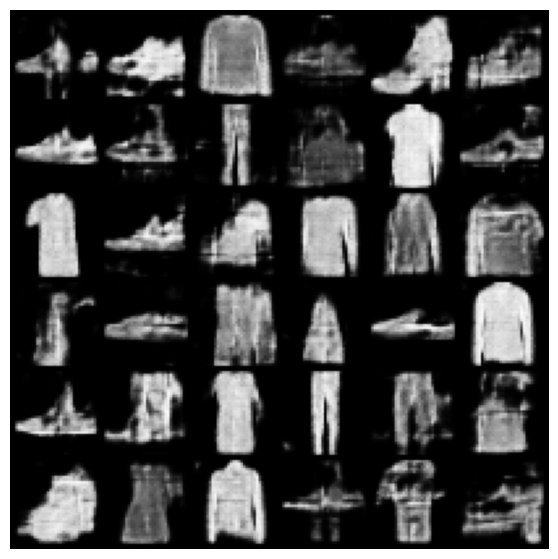

Archivos:
- resultados_dcgan/epoch_04.png
- resultados_dcgan/epoch_05.png
- resultados_dcgan/muestras_finales.png
- resultados_dcgan/perdidas.csv
- resultados_dcgan/curvas_perdida.png
- resultados_dcgan/epoch_02.png
- resultados_dcgan/epoch_01.png
- resultados_dcgan/epoch_03.png
- resultados_dcgan/modelo_dcgan.pt


In [ ]:
assert history, 'Ejecuta primero el entrenamiento.'
plt.figure(figsize=(8,4))
plt.plot([x['epoch'] for x in history],[x['loss_d'] for x in history],label='Discriminador')
plt.plot([x['epoch'] for x in history],[x['loss_g'] for x in history],label='Generador')
plt.xlabel('Época');plt.ylabel('Pérdida');plt.legend();plt.grid(alpha=.2);plt.tight_layout()
plt.savefig(OUT/'curvas_perdida.png',dpi=160);plt.show()
G.eval()
with torch.no_grad(): generated=(G(torch.randn(36,LATENT_DIM,1,1,device=DEVICE)).cpu()+1)/2
save_image(generated,OUT/'muestras_finales.png',nrow=6)
plt.figure(figsize=(7,7));plt.axis('off')
plt.imshow(make_grid(generated,nrow=6).permute(1,2,0).numpy());plt.show()
print('Archivos:',*[str(x) for x in OUT.iterdir()],sep='\n- ')

In [ ]:
import shutil
shutil.make_archive('evidencias_dcgan','zip',OUT)
try:
    from google.colab import files
    files.download('evidencias_dcgan.zip')
except ImportError:
    print('Archivo guardado localmente: evidencias_dcgan.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>